In [117]:
import os
from pathlib import Path
if Path.cwd().name == "Analysis":
    os.chdir("..")
print(Path.cwd())

/Users/emmamaenhout/Desktop/Channel Islands/Fall 2026/398_ocean


In [118]:

import duckdb
con = duckdb.connect("ocean.duckdb", read_only=True)

In [119]:
con.sql("SHOW TABLES").df()

,name
0,chl_dineof
1,chl_erd
2,cuti
3,glider
4,kelp
5,kelp_anomaly
6,kelp_quarter
7,pdo
8,photo
9,rain


In [120]:
import numpy as np
from matplotlib import pyplot
import pandas as pd

In [95]:
import rasterio

# Open the TIFF file for reading
with rasterio.open('/Users/emmamaenhout/Desktop/Channel Islands/Fall 2026/398_ocean/datasets/bathymetrics_ncei.tif') as src:
    # Read the first band as a NumPy array
    band_1 = src.read(1)

    print('Width:', src.width)
    print('Height:', src.height)
    print('Coordinate Reference System (CRS):', src.crs)
    print('Array shape:', band_1.shape)


Width: 6000
Height: 3018
Coordinate Reference System (CRS): EPSG:4326
Array shape: (3018, 6000)


/var/folders/5h/vhxcqvpj4jb5kdfz5yfnc6f40000gn/T/ipykernel_20597/1869433312.py:6: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  band_1 = src.read(1)


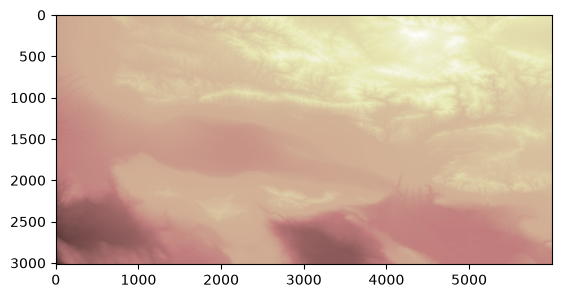

In [96]:
from matplotlib import pyplot
pyplot.imshow(band_1, cmap='pink')

pyplot.show()

---

Looking at the new datasets and how to get new tables from SQL columns

In [18]:
sst =  con.execute("SELECT * FROM 'sst'").df()

In [19]:
photo =  con.execute("SELECT * FROM 'photo'").df()

In [13]:
sst_anomaly =  con.execute("SELECT * FROM 'sst_anomaly'").df()

In [15]:
sst_climate_pre =  con.execute("SELECT * FROM 'sst_clim_pre'").df()

In [16]:
sst_climate_post =  con.execute("SELECT * FROM 'sst_clim_post'").df()

In [17]:
sst_monthly = con.execute("SELECT * FROM 'sst_monthly'").df()

In [56]:
kelp_anomaly = con.execute("SELECT * FROM 'kelp_anomaly'").df()

In [58]:
kelp_quarter = con.execute("SELECT * FROM 'kelp_quarter'").df()

In [102]:
reef_sites = con.execute("SELECT * FROM 'reef_sites'").df()

In [103]:
reef_species = con.execute("SELECT * FROM 'reef_species'").df()

In [104]:
species_ind = con.execute("SELECT * FROM 'species_ind'").df()

In [121]:
reef_species_sites = con.execute("SELECT * FROM 'reef_species_sites'").df()

--- 

Seeing how temperature has changed. </br>
Will be last time running it in python will work on aggregating this is SQL that way it isn't running everything in pandas,

In [20]:
sst_average = sst.groupby([ 'ts', 'lat', 'lon']).agg({'sst_c': 'mean'}).reset_index()

In [21]:
sst_average_by_date = sst.groupby([ 'ts']).agg({'sst_c': 'mean'}).reset_index()

<Axes: title={'center': 'Average Sea Surface Temperature Over Time 2008 - 2026'}, xlabel='ts'>

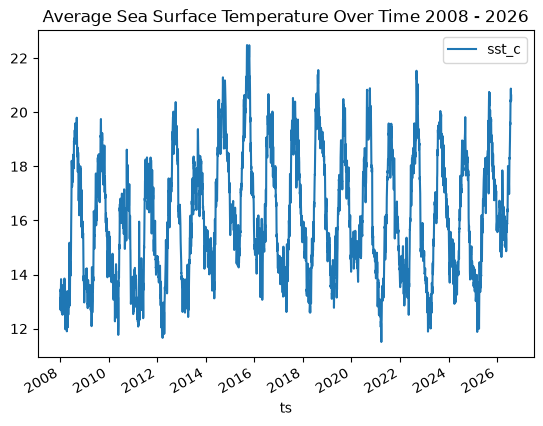

In [22]:
sst_average_by_date.plot(x="ts", y="sst_c", kind="line", title="Average Sea Surface Temperature Over Time 2008 - 2026")

In [27]:
photo_average_by_date = photo.groupby(['ts']).agg({'kdpar': 'mean'}).reset_index()

<Axes: title={'center': 'Average Sea Surface Temperature Over Time 2008 - 2026'}, xlabel='ts'>

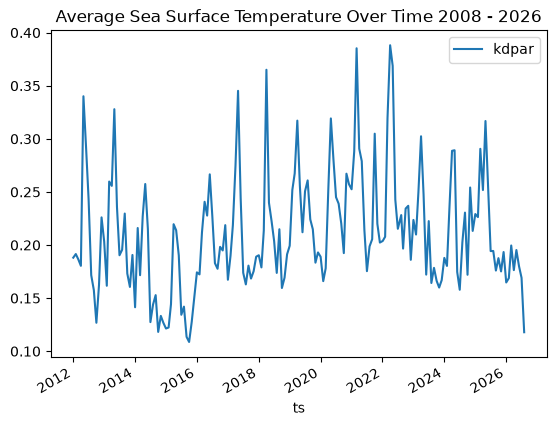

In [28]:
photo_average_by_date.plot(x="ts", y="kdpar", kind="line", title="Average Sea Surface Temperature Over Time 2008 - 2026")

In [45]:
print(sst_anomaly)

           lat     lon monthly_date  mean_sst_c   clim_sst  anomaly_c_pre  \
0        33.69 -120.52   2008-01-01   12.715710  13.502699      -0.786989   
1        33.69 -120.30   2016-01-01   14.693355  13.517414       1.175941   
2        33.70 -120.43   2026-01-01   16.062387  13.483710       2.578677   
3        33.70 -119.60   2017-01-01   14.507677  13.960253       0.547425   
4        33.70 -119.58   2016-01-01   15.238710  13.973419       1.265290   
...        ...     ...          ...         ...        ...            ...   
2334805  34.07 -120.08   2009-04-01   12.439200  12.442222      -0.003022   
2334806  34.07 -119.96   2025-04-01   13.015567  12.663867       0.351700   
2334807  34.07 -119.65   2021-04-01   13.244033  13.195906       0.048128   
2334808  34.08 -120.45   2019-04-01   13.292267  12.134289       1.157978   
2334809  34.08 -120.13   2013-04-01   12.693633  12.361711       0.331922   

         anomaly_c_post  
0             -1.429975  
1              0.477416

<Axes: title={'center': 'Sea Surface Temperature Anomaly 2008–2026'}, xlabel='monthly_date'>

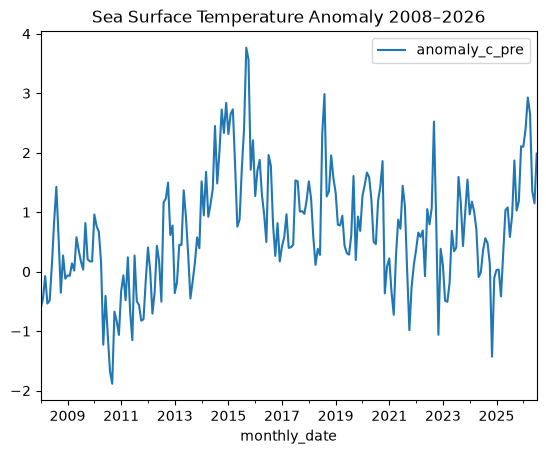

In [44]:
df = con.sql("""
    SELECT monthly_date, avg(anomaly_c_pre) AS anomaly_c_pre
    FROM sst_anomaly
    GROUP BY monthly_date
    ORDER BY monthly_date
""").df()

df.plot(x="monthly_date", y="anomaly_c_pre", kind="line",
        title="Sea Surface Temperature Anomaly 2008–2026")

<Axes: title={'center': 'Sea Surface Temperature Anomaly 2008–2026'}, xlabel='monthly_date'>

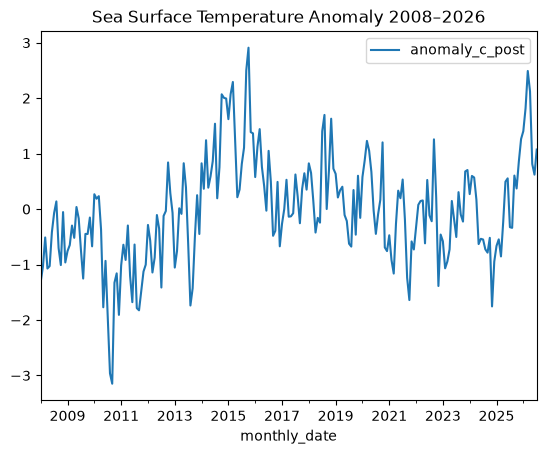

In [46]:
df = con.sql("""
    SELECT monthly_date, avg(anomaly_c_post) AS anomaly_c_post
    FROM sst_anomaly
    GROUP BY monthly_date
    ORDER BY monthly_date
""").df()

df.plot(x="monthly_date", y="anomaly_c_post", kind="line",
        title="Sea Surface Temperature Anomaly 2008–2026")

In [47]:
warming = con.sql("""
    SELECT pre.lat,
           pre.lon,
           avg(post.clim_sst - pre.clim_sst) AS warming_c
    FROM sst_clim_pre AS pre
    JOIN sst_clim_post AS post
        ON  pre.lat = post.lat
        AND pre.lon = post.lon
        AND pre.month_num = post.month_num
    GROUP BY pre.lat, pre.lon
""").df()

print(len(warming))
warming.describe()

9949


,lat,lon,warming_c
count,9949.000000,9949.000000,9949.000000
mean,34.037573,-119.819735,0.716368
std,0.217644,0.430327,0.054288
min,33.690000,-120.520000,0.526829
25%,33.850000,-120.200000,0.680752
50%,34.030000,-119.840000,0.717458
75%,34.220000,-119.470000,0.758299
max,34.510000,-118.980000,0.812448


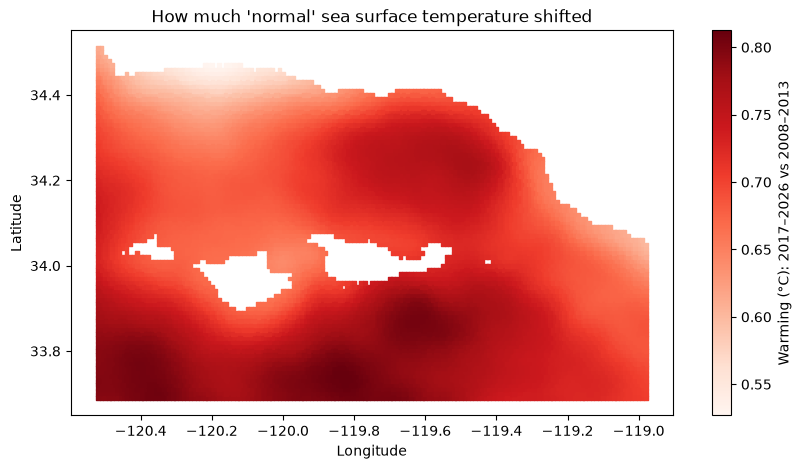

In [51]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(warming.lon, warming.lat, c=warming.warming_c,
                cmap="Reds", s=7, marker="s")
fig.colorbar(sc, label="Warming (°C): 2017–2026 vs 2008–2013")
ax.set_aspect(1.2)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("How much 'normal' sea surface temperature shifted")
plt.show()

---
### Photosysthesis -kdpar 

In [60]:
kelp_anomaly

,lat,lon,quarterly_kelp,mean_biomass_kg,mean_area_m2,clim_biomass_kg,clim_area_m2,anomaly_biomass_kg,anomaly_area_m2
0,34.440266,-120.377373,2009-07-01,0.0,0.0,16.888889,1.944444,-16.888889,-1.944444
1,34.445676,-120.377264,2009-07-01,0.0,0.0,29.222222,4.166667,-29.222222,-4.166667
2,34.438393,-120.376644,2009-07-01,0.0,0.0,0.000000,0.000000,0.000000,0.000000
3,34.068383,-120.361554,2009-07-01,0.0,0.0,229.214286,32.142857,-229.214286,-32.142857
4,34.440833,-120.376416,2009-07-01,0.0,0.0,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
8119201,33.990907,-119.532883,2020-04-01,0.0,0.0,0.000000,0.000000,0.000000,0.000000
8119202,33.994962,-119.533004,2020-04-01,0.0,0.0,24.000000,2.833333,-24.000000,-2.833333
8119203,34.393913,-119.544969,2020-04-01,0.0,0.0,297.055556,41.111111,-297.055556,-41.111111
8119204,34.389596,-119.544512,2020-04-01,0.0,0.0,52.388889,6.888889,-52.388889,-6.888889


<Axes: title={'center': 'Kelp Biomass Anomaly 2008–2026'}, xlabel='quarterly_kelp'>

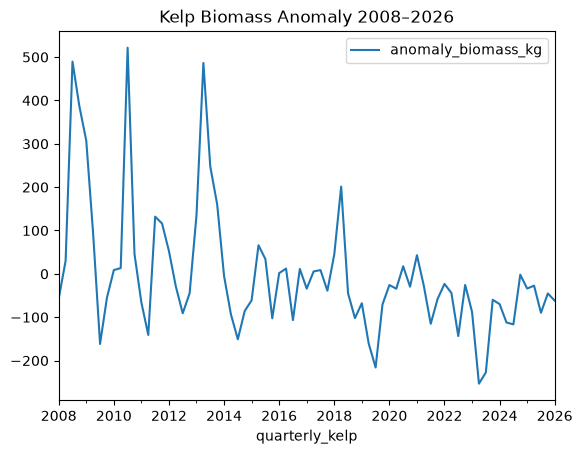

In [67]:
kelp_ts = con.sql("""
    SELECT quarterly_kelp,
           avg(anomaly_biomass_kg) AS anomaly_biomass_kg, 
    FROM kelp_anomaly
    GROUP BY quarterly_kelp
    ORDER BY quarterly_kelp
""").df()

kelp_ts.plot(x="quarterly_kelp", y="anomaly_biomass_kg", kind="line",
             title="Kelp Biomass Anomaly 2008–2026")

<Axes: title={'center': 'Kelp Biomass Anomaly 2008–2026'}, xlabel='quarterly_kelp'>

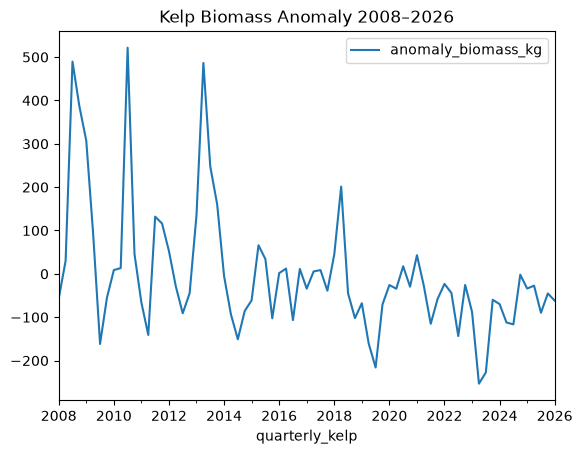

In [69]:
kelp_ts.plot(x="quarterly_kelp", y="anomaly_biomass_kg", kind="line",
             title="Kelp Biomass Anomaly 2008–2026")

In [71]:
kelp_years = con.sql("""
    SELECT 
         year(quarterly_kelp) AS year,
         avg(anomaly_biomass_kg) AS anomaly_biomass_kg_average, 
         CASE WHEN anomaly_biomass_kg_average > 0 then 'more' ELSE 'less' END AS anomaly_biomass_direction
    FROM kelp_anomaly
    GROUP BY year(quarterly_kelp)
    ORDER BY year
""").df()

<Axes: xlabel='year'>

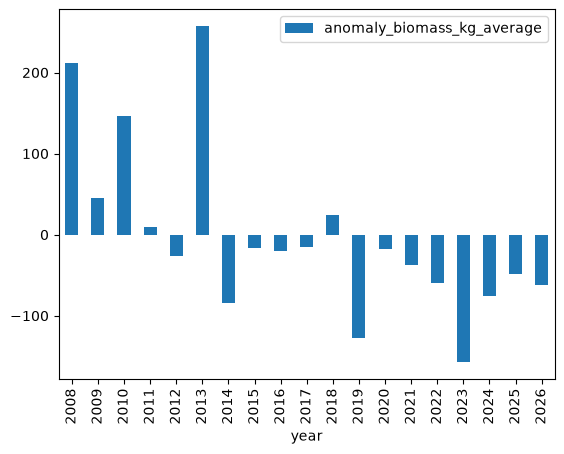

In [73]:
kelp_years.plot(x="year", y="anomaly_biomass_kg_average", kind="bar")

In [74]:
kelp_map = con.sql("""
    SELECT lat,
           lon,
           avg(mean_biomass_kg) AS mean_biomass_kg
    FROM kelp_quarter
    GROUP BY lat, lon
    HAVING avg(mean_biomass_kg) > 0
""").df()

print(len(kelp_map))
kelp_map.describe()

94011


,lat,lon,mean_biomass_kg
count,94011.000000,94011.000000,94011.000000
mean,34.114574,-120.120496,243.104349
std,0.201003,0.291521,299.300594
min,33.890610,-120.519864,0.835616
25%,33.984639,-120.357394,40.397260
50%,34.019242,-120.201504,129.000000
75%,34.393418,-119.930465,328.979159
max,34.509994,-118.980464,3231.557143


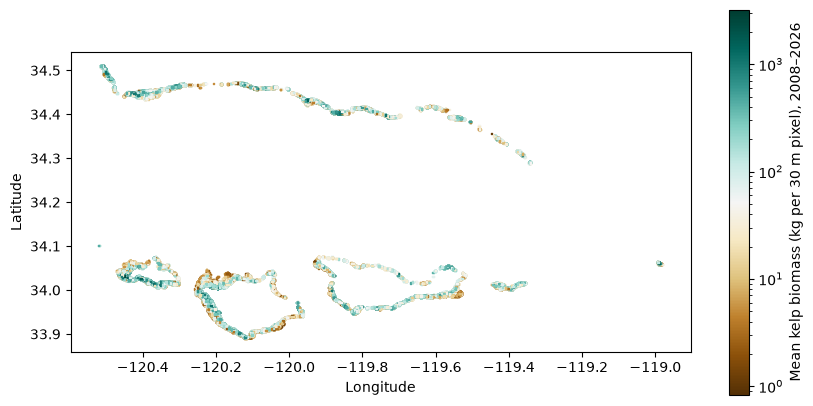

In [81]:
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(kelp_map.lon, kelp_map.lat, c=kelp_map.mean_biomass_kg,
                cmap="BrBG", s=1, marker="s", norm=LogNorm())

ax.set_aspect(1.2)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.colorbar(sc, label="Mean kelp biomass (kg per 30 m pixel), 2008–2026")

plt.show()

In [82]:
kelp_change = con.sql("""
    SELECT lat,
           lon,
           avg(CASE WHEN year(quarterly_kelp) BETWEEN 2008 AND 2013
                    THEN mean_biomass_kg END) AS pre,
           avg(CASE WHEN year(quarterly_kelp) BETWEEN 2017 AND 2025
                    THEN mean_biomass_kg END) AS post,
           post - pre AS change_kg
    FROM kelp_quarter
    GROUP BY lat, lon
""").df()

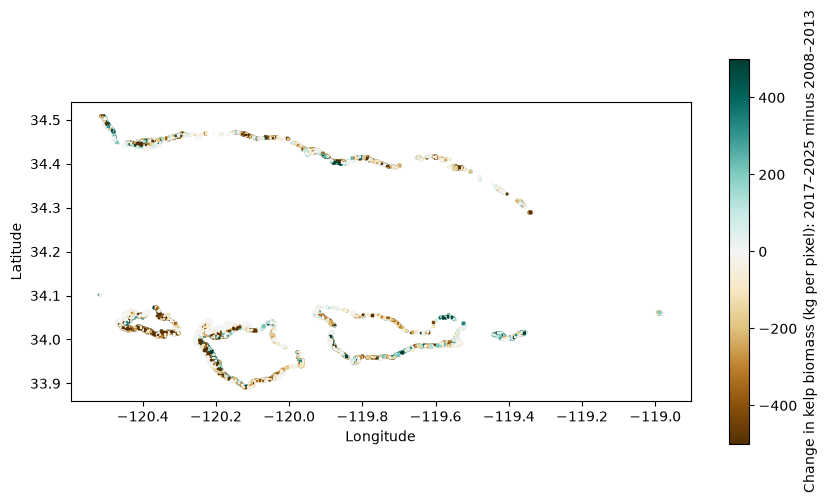

In [87]:
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(kelp_change.lon, kelp_change.lat, c=kelp_change.change_kg,
                cmap="BrBG", s=1, marker="s", vmin=-500, vmax=500)
fig.colorbar(sc, label="Change in kelp biomass (kg per pixel): 2017–2025 minus 2008–2013")

ax.set_aspect(1.2)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")


plt.show()

--- 
### reef data
looking to where the data was collected and how it is influencing everything 

In [105]:
reef_sites

,site,site_name,lat,lon
0,AQUE,Arroyo Quemado,34.46775,-120.11905
1,NAPL,Naples,34.42212,-119.95154
2,IVEE,Isla Vista,34.40278,-119.85755
3,MOHK,Mohawk,34.39407,-119.72957
4,CARP,Carpinteria,34.39163,-119.54169


In [106]:
reef_species

,species,common_name,site,year,mean_density
0,Pugettia producta,Kelp Crab,IVEE,2022,0.000000
1,Unidentifiable juvenile kelp,Unidentifiable juvenile kelp - not a unique sp...,MOHK,2022,0.291667
2,Hexagrammos decagrammus,Kelp Greenling,MOHK,2022,0.000000
3,Macrocystis pyrifera,Giant Kelp,MOHK,2022,4.913542
4,Jellyella tuberculata,Kelp Bryozoan,MOHK,2022,NaN
...,...,...,...,...,...
1651,Strongylocentrotus purpuratus,Purple Urchin,AQUE,2017,0.958333
1652,Centrostephanus coronatus,Crowned Sea Urchin,IVEE,2019,0.000000
1653,Sebastes atrovirens,Kelp Rockfish,IVEE,2019,0.000000
1654,Egregia menziesii,Feather Boa Kelp,MOHK,2019,0.000000


In [107]:
species_ind

,year,month,site,giant_kelp_density,feather_kelp_density,palm_kelp_density,purple_urchin_density,red_urchin_density
0,2008,1,AQUE,2.091667,0.000000,0.900000,0.000000,0.000000
1,2008,1,MOHK,5.733333,0.000000,4.379167,8.500000,0.333333
2,2008,1,NAPL,0.000000,0.000000,0.000000,48.166667,8.000000
3,2008,2,CARP,0.287500,0.000000,0.312500,13.500000,1.500000
4,2008,3,AQUE,1.225000,0.000000,0.925000,0.000000,0.000000
...,...,...,...,...,...,...,...,...
420,2026,2,AQUE,0.650000,0.000000,3.400000,0.166667,0.000000
421,2026,2,CARP,0.000000,0.000000,1.558333,3.166667,2.833333
422,2026,2,IVEE,3.041667,0.445833,0.500000,0.000000,0.166667
423,2026,2,MOHK,0.000000,0.000000,1.275000,2.333333,0.000000


In [133]:
reef_species_sites

,site,site_name,year,month,giant_kelp_density,feather_kelp_density,palm_kelp_density,purple_urchin_density,red_urchin_density
0,AQUE,Arroyo Quemado,2008,1,2.091667,0.0,0.900000,0.000000,0.000000
1,AQUE,Arroyo Quemado,2008,3,1.225000,0.0,0.925000,0.000000,0.000000
2,AQUE,Arroyo Quemado,2008,4,1.812500,0.0,0.737500,0.000000,0.000000
3,AQUE,Arroyo Quemado,2008,5,3.791667,0.0,29.500000,0.000000,0.000000
4,AQUE,Arroyo Quemado,2008,6,3.583333,0.0,24.975000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
420,NAPL,Naples,2025,2,5.695833,0.0,10.508333,4.833333,1.000000
421,NAPL,Naples,2025,5,9.016667,0.0,21.791667,3.666667,0.666667
422,NAPL,Naples,2025,7,7.295833,0.0,22.966667,2.833333,0.500000
423,NAPL,Naples,2025,11,4.454167,0.0,12.441667,2.000000,0.500000


In [132]:
import pandas as pd
df["survey_date"] = pd.to_datetime(dict(year=df.year, month=df.month, day=1))

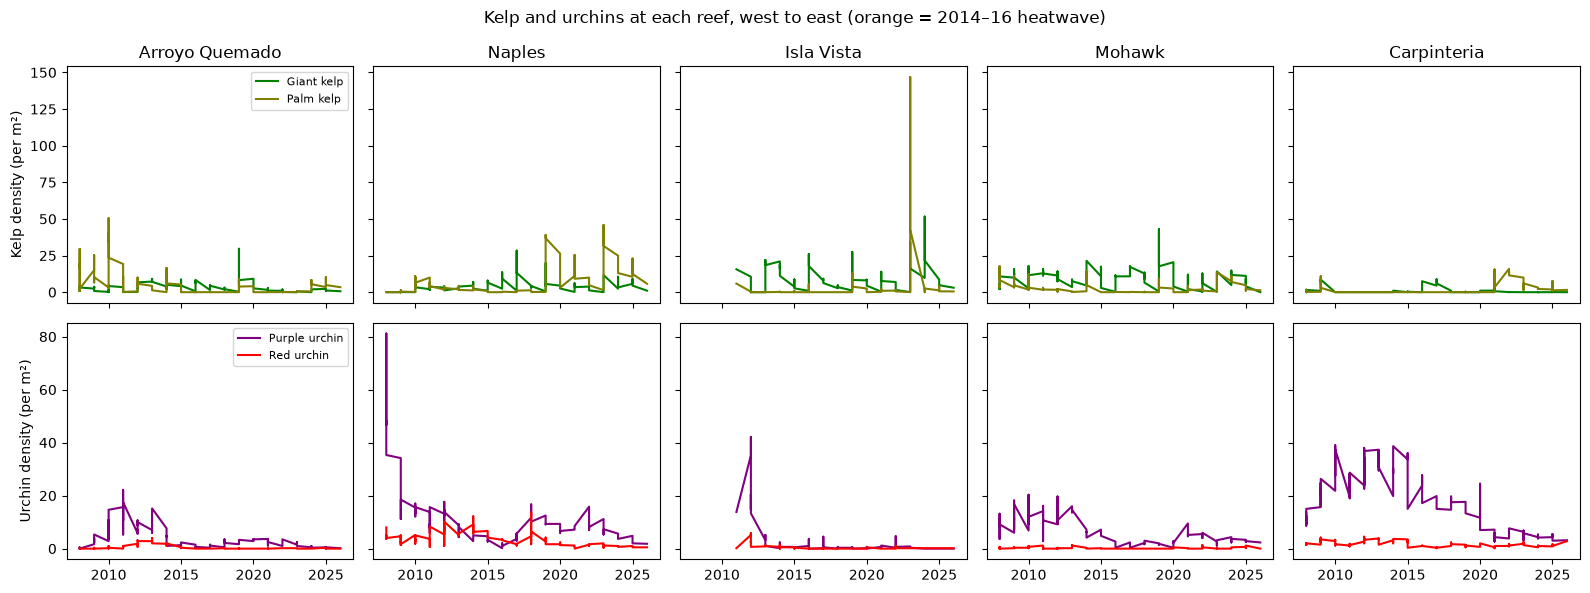

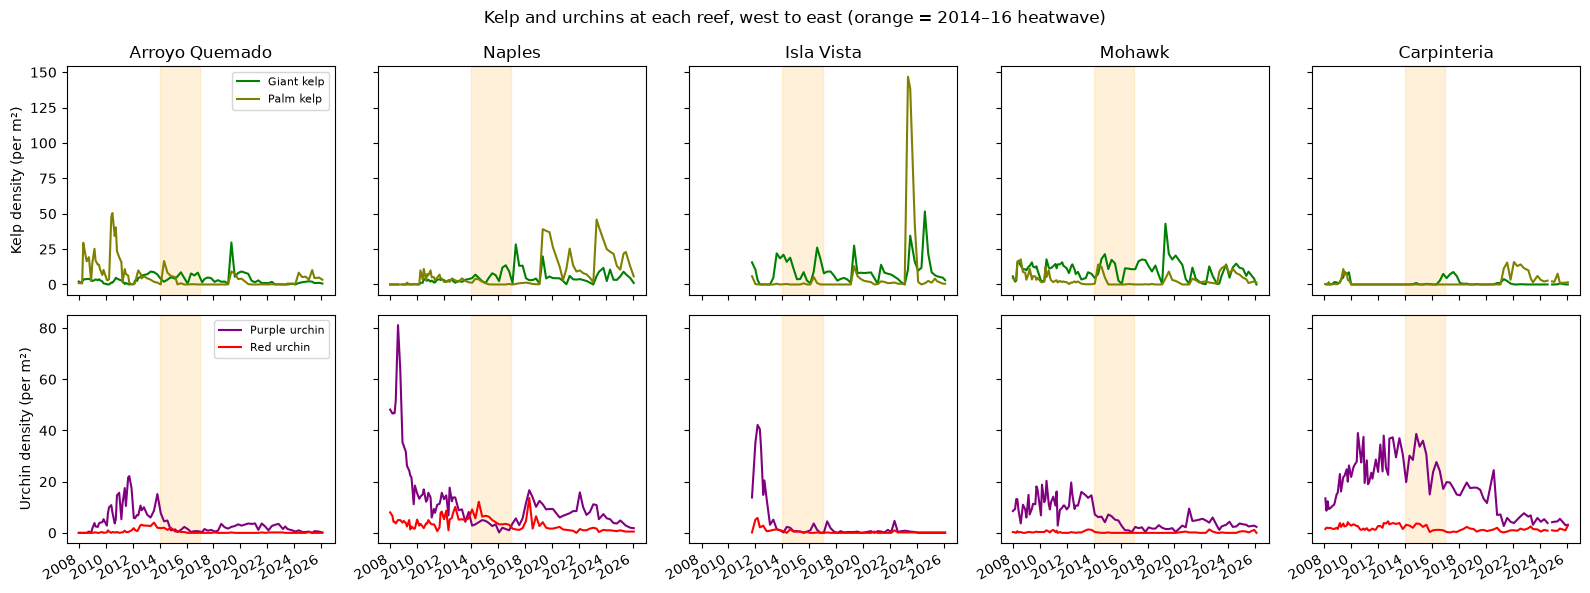

In [134]:
import pandas as pd

df = con.sql("SELECT * FROM reef_species_sites").df()
df["survey_date"] = pd.to_datetime(dict(year=df.year, month=df.month, day=1))

sites = ["AQUE", "NAPL", "IVEE", "MOHK", "CARP"]   # west to east
heat_start = pd.Timestamp("2014-01-01")
heat_end = pd.Timestamp("2016-12-31")

fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey="row")
for i, site in enumerate(sites):
    d = df[df.site == site].sort_values("survey_date")
    axes[0, i].plot(d.survey_date, d.giant_kelp_density, color="green", label="Giant kelp")
    axes[0, i].plot(d.survey_date, d.palm_kelp_density, color="olive", label="Palm kelp")
    axes[1, i].plot(d.survey_date, d.purple_urchin_density, color="purple", label="Purple urchin")
    axes[1, i].plot(d.survey_date, d.red_urchin_density, color="red", label="Red urchin")
    axes[0, i].set_title(d.site_name.iloc[0])
    for ax in axes[:, i]:
        ax.axvspan(heat_start, heat_end, color="orange", alpha=0.15)

axes[0, 0].set_ylabel("Kelp density (per m²)")
axes[1, 0].set_ylabel("Urchin density (per m²)")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.suptitle("Kelp and urchins at each reef, west to east (orange = 2014–16 heatwave)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

---



In [136]:
con.close()